# Which Sensors Warn of a Failing Wafer? SPC and Yield Analysis of the SECOM Fab Dataset
### UCI SECOM — 1,567 production runs, 590 in-line process sensors, pass/fail from final test

---

## Executive summary

**Problem.** A fab logs hundreds of in-line sensors on every production run, but only learns at final test whether the run passed. This notebook asks which sensors would have warned of a failing run, whether standard SPC charts on them can be trusted, and whether a model could flag failures in advance.

**Data.** UCI SECOM: 1,567 runs over 89 days (July–October 2008), 590 anonymised sensors, 104 failures (6.6%). After removing constant, mostly-missing and duplicated sensors, 343 sensors remain.

**Four main findings**
1. **Yield improved strongly over the period, and that trend confounds everything.** The fail rate in the first half of the runs is **8.6%** against **4.7%** in the second half (Fisher p = 0.002); the daily p-chart has 5 out-of-control days, all in the early weeks. Any sensor that drifted over those weeks looks "associated with failure" for that reason alone.
2. **13 sensors separate fails from passes after correcting for testing 343 at once, but only 6 survive removing the time trend.** 68 sensors reach raw p < 0.05 (17 expected by chance), 18 pass the Benjamini-Hochberg false-discovery bar, and 13 also have a meaningful effect (|AUC − 0.5| ≥ 0.1). Nine of the 13 are strongly tied to time. Comparing each run only with its time neighbours leaves **6 sensors in 5 independent families** (led by s059, s205/s341, s021, s033, s316). The second-strongest raw sensor, s103 (AUC 0.67), is essentially a clock.
3. **Textbook Shewhart limits over-alarm on these sensors.** Phase II points fall outside 3σ limits at a median rate of **1.4%**, five times the theoretical 0.27%, and autocorrelated sensors are much worse: s124 (lag-1 autocorrelation 0.49) puts **29%** of phase II runs beyond 3σ. Charting AR(1) residuals instead cuts that to about **7%**, better but still not in control, which says the sensor's level itself shifts.
4. **No model beats chance on future runs.** On a sealed, time-ordered test block, L1 logistic regression and gradient boosting reach PR-AUC ≈ 0.07 against a no-skill 0.055, and both sit inside the distribution of models trained on shuffled labels (permutation p ≈ 0.35–0.38). Random cross-validation inside the development block looked 3× better than chance, which is the classic over-optimism of ignoring time.

**Main recommendation.** Monitor the 5 drift-robust signal families with residual-based or EWMA charts rather than raw Shewhart limits, and investigate them with the process owners. Do **not** deploy a pass/fail prediction model on these sensors: the drift between weeks is larger than the signal. The more useful next step is collecting the process context that is missing (tool, chamber, recipe and lot IDs), which would let both the drift and the failures be explained.

**Key limitation.** Sensors are anonymised and the data is observational: findings are associations to investigate, not causes. With only 26 failures in the test block, every performance figure has wide uncertainty.

*Numbers in this summary come from the cells below (fixed seed). Model scores can differ slightly between scikit-learn versions; the final section prints the values from your live run.*

## Contents

1. Problem statement and guiding questions
2. Data provenance and data dictionary
3. Reproducible setup
4. Loading the raw data
5. Systematic data-quality audit
6. Cleaning decisions and cleaning log
7. Q1 — Is yield stable over time? (attribute control chart)
8. Q2 — Which sensors separate failing from passing runs?
9. Q3 — Do those differences survive once the time trend is removed?
10. Q4 — Can classic SPC charts on these sensors be trusted?
11. Q5 — Can a model flag failing runs before final test?
12. Answers, recommendations and limitations
13. Reproducibility record

## 1. Problem statement and guiding questions

**Context.** A wafer passes through hundreds of process steps before it is electrically tested. When a lot fails final test, the fab wants to know *which upstream signal would have warned them*, so it can tighten control on that step and stop shipping bad material further down the line. Every step is instrumented, so the problem is not a lack of data but too much of it: hundreds of sensors, most irrelevant, a few failures, and a process that keeps changing.

This is the day-to-day work of a process-control application engineer: take a customer's fab data, separate real signals from noise, and recommend what to monitor.

**Unit of analysis.** One production run (one row): 590 sensor summaries and a pass/fail result from in-house line testing.

**Guiding questions**

| # | Question | Why it matters in a fab |
|---|---|---|
| Q1 | Is the fail rate stable over the 13 weeks, or is the process drifting? | A drifting baseline confounds every sensor comparison |
| Q2 | Which sensors differ between failing and passing runs, after correcting for testing 470 sensors at once? | Candidate root-cause signals |
| Q3 | Do those differences survive once the time trend is removed? | Separates real process signals from "both changed over time" |
| Q4 | Can textbook Shewhart / EWMA control charts be trusted on these sensors? | False alarms erode trust in SPC on the line |
| Q5 | Can a model flag failing runs before final test, and is it better than chance on *future* runs? | Decides whether a virtual-test model is worth deploying |

**What this notebook is not.** The sensors are anonymised, so no finding can be tied to a named tool or step. The analysis therefore focuses on *method*: what can be trusted, what cannot, and why.

## 2. Data provenance and data dictionary

| Item | Detail |
|---|---|
| Source | UCI Machine Learning Repository, *SECOM* (McCann & Johnston, 2008), DOI 10.24432/C54305 |
| Licence | CC BY 4.0 (cite the UCI repository) |
| Primary download | `https://archive.ics.uci.edu/static/public/179/secom.zip`, verified against a pinned SHA-256 |
| Fallback mirror | GitHub `Divyavijayhaldankar/Secom_semi-conductor_manufacturing`, pinned commit, files verified by SHA-256 |
| Files | `secom.data` (1,567 × 590, space-separated, `NaN` for missing); `secom_labels.data` (label, timestamp) |
| Time span | 19 July 2008 – 17 October 2008 |

| Field | Meaning | Notes |
|---|---|---|
| `s000` … `s589` | One summary value per sensor per run | Anonymised: no names, units or specification limits |
| `label` | −1 = pass, 1 = fail (in-house line test) | Recoded to `fail` = 1 / 0 here |
| `timestamp` | Date-time of the test | Used to order runs; 33 runs share a timestamp with another run |

## 3. Reproducible setup

Everything a re-run depends on is in the next two cells: imports, the configuration (all thresholds in one place), the random seed and the data download. **Restart the kernel and run all cells in order.** The full notebook runs in about 3–6 minutes on a laptop CPU; only `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib` and `seaborn` are needed.

In [1]:
import io, json, time, zipfile, hashlib, platform, warnings, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4g}')

CONFIG = {
    'uci_url': 'https://archive.ics.uci.edu/static/public/179/secom.zip',
    'uci_zip_sha256': 'eea568baf3c2229096d7d294cf0b096b5502bd96d92c0b80a65b84714059be8e',
    'mirror_repo': 'Divyavijayhaldankar/Secom_semi-conductor_manufacturing',
    'mirror_commit': 'dacfd1bf6c66a0fc26e7e95a8695840bb3859290',
    'file_sha256': {'secom.data': '20f0e7ee434f7dcbae0eea9ffff009a2b57f42d6b0dc9a5bd4f00782c0a3374c',
                    'secom_labels.data': '126884cf453705c9e61a903fe906f0665a3b45ce3639e621edc5c93c89627e03'},
    'seed': 42,
    'max_missing_share': 0.50,      # sensors missing in more than half the runs are dropped
    'near_duplicate_rho': 0.98,     # |Spearman rho| above this = same signal measured twice
    'redundancy_rho': 0.90,         # |rho| above this groups significant sensors into one signal family
    'fdr_alpha': 0.05,              # Benjamini-Hochberg false discovery rate
    'min_auc_effect': 0.10,         # practical-importance bar: |AUC - 0.5| >= 0.10
    'detrend_window': 101,          # runs in the centred rolling median used to remove the time trend
    'phase1_runs': 500,             # first runs (by time) used to set control limits
    'ewma_lambda': 0.2, 'ewma_L': 2.86,
    'test_share': 0.30,             # last 30% of runs (by time) form the sealed test block
    'alarm_rate': 0.10,             # operating point: flag 10% of runs for review
    'bootstrap_draws': 2000,
    'n_permutations': 200,          # shuffled-label refits for logistic regression (fast)
    'n_permutations_gb': 50,        # ... and for gradient boosting (slower; 50 keeps the run to a few minutes)
}
RNG = np.random.default_rng(CONFIG['seed'])

HERE = Path.cwd()
DATA_DIR = HERE / 'data'
OUT = HERE / 'outputs'
FIG = OUT / 'figures'
for d in (DATA_DIR, OUT, FIG): d.mkdir(parents=True, exist_ok=True)

C_PASS, C_FAIL, C_GREY, C_ACC = '#0072B2', '#D55E00', '#777777', '#009E73'   # Okabe-Ito (colour-blind safe)
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.95)
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 11})

def savefig(fig, name):
    """Save every figure to outputs/figures and show it inline."""
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

def note(text):
    display(Markdown(text))

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()

def bh(p):
    """Benjamini-Hochberg adjusted p-values (q-values; controls the false discovery rate)."""
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1.0)
    return out

print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | '
      f'scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}')
print('Working folder:', HERE)

Python 3.13.17 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2
Working folder: secom-spc-yield-analysis


**Getting the data.** The next cell downloads the official UCI archive and checks its SHA-256 before extracting anything. If UCI is unreachable, it falls back to a GitHub mirror pinned to one commit and checks each file's SHA-256. It runs once; later runs reuse `data/`. If your network blocks both, download `secom.zip` from the UCI page by hand and put `secom.data` and `secom_labels.data` in the `data/` folder next to this notebook.

In [2]:
FILES = ('secom.data', 'secom_labels.data')

def get_data():
    if all((DATA_DIR / f).exists() for f in FILES):
        return 'already present'
    try:
        archive = DATA_DIR / 'secom.zip'
        urllib.request.urlretrieve(CONFIG['uci_url'], archive)
        if sha256(archive) != CONFIG['uci_zip_sha256']:
            archive.unlink(); raise ValueError('UCI archive hash mismatch')
        with zipfile.ZipFile(archive) as zf:
            for f in FILES: (DATA_DIR / f).write_bytes(zf.read(f))
        return 'UCI archive'
    except Exception as e:
        print(f'UCI download failed ({e}); trying the pinned GitHub mirror')
    base = f"https://raw.githubusercontent.com/{CONFIG['mirror_repo']}/{CONFIG['mirror_commit']}/"
    for f in FILES:
        urllib.request.urlretrieve(base + f, DATA_DIR / f)
    return 'GitHub mirror'

source = get_data()
hashes = {f: sha256(DATA_DIR / f) for f in FILES}
for f, h in hashes.items():
    status = 'OK' if h == CONFIG['file_sha256'][f] else 'DIFFERENT FROM PINNED HASH - check the source'
    print(f'{f:<20} sha256 {h[:16]}…  {status}')
print('Data source:', source)

secom.data           sha256 20f0e7ee434f7dcb…  OK
secom_labels.data    sha256 126884cf453705c9…  OK
Data source: already present


## 4. Loading the raw data

The raw files are never modified. Sensor columns are named `s000`–`s589` by their position in the file, so any finding can be traced back to the original column. Runs are sorted by timestamp (a stable sort keeps the file order for the 33 tied timestamps), and every later step uses this time order.

In [3]:
X_raw = pd.read_csv(DATA_DIR / 'secom.data', sep=' ', header=None)
X_raw.columns = [f's{i:03d}' for i in range(X_raw.shape[1])]
lab = pd.read_csv(DATA_DIR / 'secom_labels.data', sep=' ', header=None, names=['label', 'timestamp'])
lab['timestamp'] = pd.to_datetime(lab['timestamp'], format='%d/%m/%Y %H:%M:%S')
lab['fail'] = (lab['label'] == 1).astype(int)
assert len(X_raw) == len(lab), 'sensor and label files must have the same number of rows'

order = lab['timestamp'].sort_values(kind='stable').index
X_raw = X_raw.loc[order].reset_index(drop=True)
lab = lab.loc[order].reset_index(drop=True)
lab['run'] = np.arange(len(lab))
SENSORS_ALL = list(X_raw.columns)
y = lab['fail'].to_numpy()

overview = pd.DataFrame({
    'runs': [len(lab)], 'sensors': [X_raw.shape[1]], 'fails': [int(y.sum())], 'fail rate %': [100 * y.mean()],
    'first run': [lab.timestamp.min()], 'last run': [lab.timestamp.max()],
    'days covered': [(lab.timestamp.max() - lab.timestamp.min()).days],
    'missing cells %': [100 * X_raw.isna().to_numpy().mean()]})
display(overview)

,runs,sensors,fails,fail rate %,first run,last run,days covered,missing cells %
0,1567,590,104,6.637,2008-07-19 11:55:00,2008-10-17 06:07:00,89,4.538


## 5. Systematic data-quality audit

The audit runs **before any change** so the baseline profile is honest. Each check asks: is this a data problem, or legitimate behaviour of the process? Findings are collected in an issue table (§5.7).

### 5.1 Types, constant and near-constant sensors

In [4]:
issues = []
nun = X_raw.nunique(dropna=True)
const = nun[nun <= 1].index.tolist()
std = X_raw.std()
cv = (std / X_raw.mean().abs()).replace([np.inf], np.nan)
low_var = [c for c in SENSORS_ALL if c not in const and nun[c] <= 3]
print(f'All columns numeric: {all(pd.api.types.is_numeric_dtype(X_raw[c]) for c in SENSORS_ALL)}')
print(f'Constant sensors (one value, or all missing): {len(const)}')
print(f'Sensors with only 2-3 distinct values: {len(low_var)}')
print(f'Negative values present in {int((X_raw < 0).any().sum())} sensors (plausible: offsets / differences, not errors)')
issues.append(('Constant sensors', f'{len(const)} of 590 take a single value', 'Drop', 'Cannot carry information'))

All columns numeric: True
Constant sensors (one value, or all missing): 116
Sensors with only 2-3 distinct values: 6
Negative values present in 36 sensors (plausible: offsets / differences, not errors)


### 5.2 Missing values — how much, where, and is it random?

4.5% of cells are missing. In fab data missingness is rarely random: a sensor that was not logged on a tool, or a measurement only taken on sampled lots, leaves *structured* gaps. The three panels show the share missing per sensor, the number of missing sensors per run, and whether whole blocks of sensors go missing together.

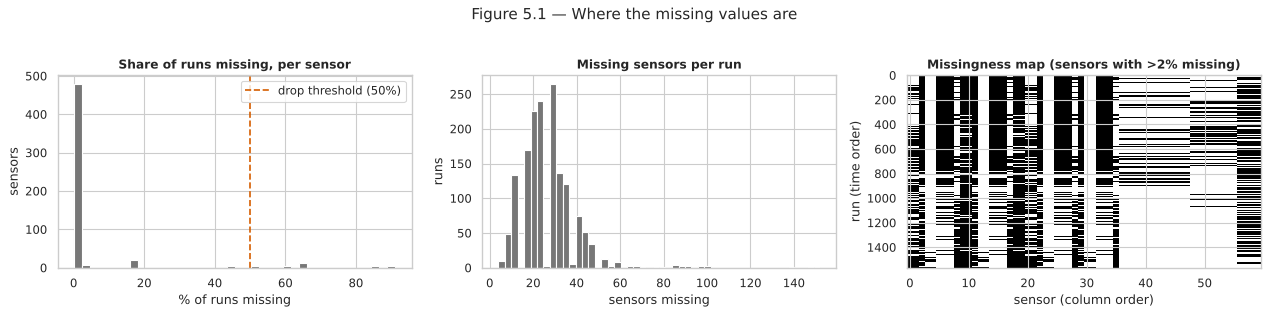

Sensors with any missing value: 538;  >50% missing: 28
Distinct missingness patterns among those sensors: 35 (sensors sharing a pattern go missing on exactly the same runs)
Missing sensors per run: median 24, max 152


In [5]:
miss = X_raw.isna()
miss_share = miss.mean()
miss_row = miss.sum(axis=1)
patterns = miss.loc[:, miss_share > 0].T.drop_duplicates()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(miss_share[miss_share > 0] * 100, bins=40, color=C_GREY)
axes[0].axvline(CONFIG['max_missing_share'] * 100, color=C_FAIL, ls='--', label='drop threshold (50%)')
axes[0].set(title='Share of runs missing, per sensor', xlabel='% of runs missing', ylabel='sensors'); axes[0].legend()
axes[1].hist(miss_row, bins=50, color=C_GREY); axes[1].set(title='Missing sensors per run', xlabel='sensors missing', ylabel='runs')
axes[2].imshow(miss.loc[:, miss_share > 0.02].to_numpy(), aspect='auto', cmap='Greys', interpolation='nearest')
axes[2].set(title='Missingness map (sensors with >2% missing)', xlabel='sensor (column order)', ylabel='run (time order)')
fig.suptitle('Figure 5.1 — Where the missing values are', y=1.03); fig.tight_layout(); savefig(fig, '05_01_missingness')

print(f'Sensors with any missing value: {(miss_share > 0).sum()};  >50% missing: {(miss_share > CONFIG["max_missing_share"]).sum()}')
print(f'Distinct missingness patterns among those sensors: {len(patterns)} (sensors sharing a pattern go missing on exactly the same runs)')
print(f'Missing sensors per run: median {miss_row.median():.0f}, max {miss_row.max()}')

**Is missingness itself related to failure?** If a measurement is skipped more often on runs that later fail (or the reverse), the *fact* of missingness is a signal and must not be silently imputed away. Fisher's exact test per sensor, with Benjamini-Hochberg correction across sensors:

In [6]:
rows = []
for c in miss_share[(miss_share > 0) & (miss_share < 1)].index:
    m = miss[c].to_numpy()
    tab = [[int((m & (y == 1)).sum()), int((~m & (y == 1)).sum())], [int((m & (y == 0)).sum()), int((~m & (y == 0)).sum())]]
    p = stats.fisher_exact(tab)[1]
    rows.append({'sensor': c, 'missing %': 100 * m.mean(), 'fail rate when missing %': 100 * y[m].mean() if m.any() else np.nan,
                 'fail rate when present %': 100 * y[~m].mean(), 'p': p})
miss_test = pd.DataFrame(rows); miss_test['q'] = bh(miss_test['p'])
miss_sig = miss_test[miss_test.q < CONFIG['fdr_alpha']].sort_values('p')
print(f'{len(miss_test)} sensors tested; {len(miss_sig)} have a missingness rate that differs between pass and fail (BH q < 0.05)')
display(miss_test.sort_values('p').head(8).round(4))
print(f'Missing sensors per run — fails: median {miss_row[y == 1].median():.0f}, passes: median {miss_row[y == 0].median():.0f}, '
      f'Mann-Whitney p = {stats.mannwhitneyu(miss_row[y == 1], miss_row[y == 0]).pvalue:.2f}')
issues.append(('Missing values', f'{(miss_share > 0).sum()} sensors affected, {len(patterns)} block patterns; '
               f'{(miss_share > CONFIG["max_missing_share"]).sum()} sensors >50% missing',
               'Drop >50% sensors; impute the rest inside model folds; keep missing-indicators',
               f'{len(miss_sig)} sensors have failure-related missingness'))

538 sensors tested; 0 have a missingness rate that differs between pass and fail (BH q < 0.05)


,sensor,missing %,fail rate when missing %,fail rate when present %,p,q
71,s072,50.67,4.534,8.797,0.0008,0.1023
72,s073,50.67,4.534,8.797,0.0008,0.1023
322,s345,50.67,4.534,8.797,0.0008,0.1023
323,s346,50.67,4.534,8.797,0.0008,0.1023
359,s385,45.63,4.615,8.333,0.0031,0.209
108,s112,45.63,4.615,8.333,0.0031,0.209
482,s519,45.63,4.615,8.333,0.0031,0.209
232,s247,45.63,4.615,8.333,0.0031,0.209


Missing sensors per run — fails: median 24, passes: median 24, Mann-Whitney p = 0.35


**Reading §5.2.** Missingness is strongly structured: the gaps fall into about 35 block patterns, so whole groups of sensors go missing on the same runs, the signature of measurement steps that are skipped or sampled rather than random dropouts. No sensor's missingness is linked to failure after the false-discovery correction. The strongest raw case (s072 and three companions, missing on 51% of runs) has a lower fail rate when missing (4.5% vs 8.8%), but those sensors are missing far more often late in the period (64% vs 38% in the first half), when yield was better. That is a time effect again (§7), not evidence that skipping the measurement prevents failures.

### 5.3 Duplicate runs and duplicate sensors

Two kinds of duplicate are possible: the same run stored twice (identical rows), and the same physical quantity logged under two sensor columns (identical or near-identical columns). The second is common in fab data, where a value is logged by both the tool and the host system.

In [7]:
dup_rows = int(X_raw.duplicated().sum())
keep_cols = [c for c in SENSORS_ALL if c not in const]
exact_dup_cols = X_raw[keep_cols].T.duplicated()
rho_all = X_raw[keep_cols].rank().corr(min_periods=200).abs()   # Spearman = Pearson on ranks
upper = rho_all.where(np.triu(np.ones(rho_all.shape, bool), k=1))
pairs = upper.stack()
near_pairs = pairs[pairs > CONFIG['near_duplicate_rho']].sort_values(ascending=False)
# greedy: keep the first sensor of each near-duplicate pair (lower missingness wins)
drop_dupe = set()
for (a, b), r in near_pairs.items():
    if a in drop_dupe or b in drop_dupe: continue
    drop_dupe.add(b if miss_share[a] <= miss_share[b] else a)
print(f'Duplicate runs (identical rows): {dup_rows}')
print(f'Exactly duplicated sensor columns: {int(exact_dup_cols.sum())}')
print(f'Sensor pairs with |Spearman rho| > {CONFIG["near_duplicate_rho"]}: {len(near_pairs)}  ->  {len(drop_dupe)} redundant sensors')
display(near_pairs.head(8).rename('|rho|').reset_index().rename(columns={'level_0': 'sensor A', 'level_1': 'sensor B'}).round(4))
issues.append(('Near-duplicate sensors', f'{len(near_pairs)} pairs with |rho| > {CONFIG["near_duplicate_rho"]}',
               f'Flag {len(drop_dupe)} redundant copies; drop those still present after §6 steps', 'Avoids counting one signal several times'))

Duplicate runs (identical rows): 0
Exactly duplicated sensor columns: 0
Sensor pairs with |Spearman rho| > 0.98: 138  ->  111 redundant sensors


,sensor A,sensor B,|rho|
0,s074,s206,1
1,s074,s209,1
2,s074,s347,1
3,s074,s342,1
4,s074,s478,1
5,s209,s478,1
6,s342,s347,1
7,s206,s209,1


### 5.4 Timestamps: order, ties and gaps

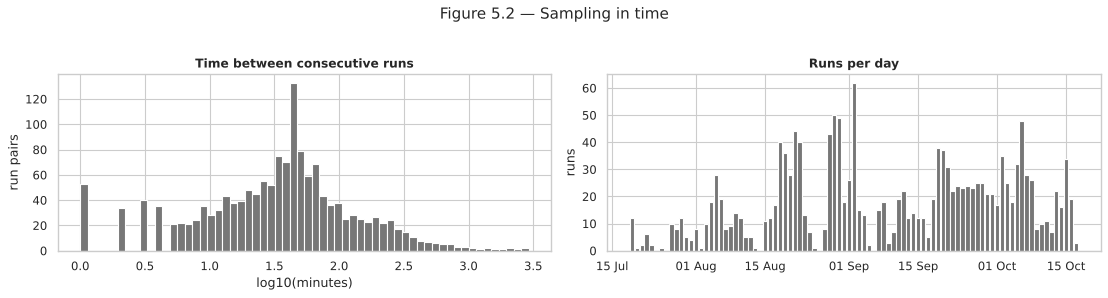

Tied timestamps: 33;  gaps longer than 12 h: 21 (longest 48.6 h);  days with no runs: 5 of 91


In [8]:
dt_min = lab['timestamp'].diff().dt.total_seconds() / 60
ties = int(lab['timestamp'].duplicated().sum())
gaps = dt_min[dt_min > 12 * 60]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
axes[0].hist(np.log10(dt_min[dt_min > 0]), bins=60, color=C_GREY)
axes[0].set(title='Time between consecutive runs', xlabel='log10(minutes)', ylabel='run pairs')
daily = lab.set_index('timestamp')['fail'].resample('D').size()
axes[1].bar(daily.index, daily.to_numpy(), width=0.9, color=C_GREY)
axes[1].set(title='Runs per day', ylabel='runs'); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle('Figure 5.2 — Sampling in time', y=1.03); fig.tight_layout(); savefig(fig, '05_02_time')
print(f'Tied timestamps: {ties};  gaps longer than 12 h: {len(gaps)} (longest {gaps.max() / 60:.1f} h);  '
      f'days with no runs: {(daily == 0).sum()} of {len(daily)}')
issues.append(('Timestamps', f'{ties} ties, {len(gaps)} gaps > 12 h, uneven daily volume',
               'Stable sort by time; analyse in run order, aggregate by day for yield', 'Throughput is uneven: weekly rates have varying precision'))

### 5.5 Class balance

In [9]:
print(f'Fails: {y.sum()} of {len(y)} runs ({100 * y.mean():.2f}%) — a no-skill classifier has PR-AUC = {y.mean():.3f}')
issues.append(('Class imbalance', f'{y.sum()} fails ({100 * y.mean():.1f}%)', 'Use PR-AUC, recall at a fixed alarm rate; class weights',
               'Accuracy is meaningless (93% by always predicting pass)'))

Fails: 104 of 1567 runs (6.64%) — a no-skill classifier has PR-AUC = 0.066


### 5.6 Outliers

With no units or specification limits, an "outlier" cannot be called an error on physical grounds. Extreme values are counted per sensor with a robust rule (more than 6 robust standard deviations from the median, using the MAD) but **not removed**: in a fab, an extreme reading on a failing run is exactly what we want to find. Rank-based statistics are used in §8–9 so that a few extreme values cannot dominate.

In [10]:
med = X_raw.median(); mad = (X_raw - med).abs().median() * 1.4826
robust_z = ((X_raw - med) / mad.replace(0, np.nan)).abs()
n_extreme = (robust_z > 6).sum()
print(f'Sensors with at least one |robust z| > 6: {(n_extreme > 0).sum()};  cells affected: {int(n_extreme.sum())} '
      f'({100 * n_extreme.sum() / X_raw.notna().to_numpy().sum():.2f}% of observed cells)')
ext_run = (robust_z > 6).sum(axis=1)
print(f'Extreme cells per run — fails: mean {ext_run[y == 1].mean():.1f}, passes: mean {ext_run[y == 0].mean():.1f}')
issues.append(('Extreme values', f'{(n_extreme > 0).sum()} sensors have |robust z| > 6', 'Kept; rank-based tests and tree models',
               'No physical basis to delete them'))

Sensors with at least one |robust z| > 6: 349;  cells affected: 9896 (1.12% of observed cells)
Extreme cells per run — fails: mean 7.6, passes: mean 6.2


### 5.7 Issue table

In [11]:
issue_table = pd.DataFrame(issues, columns=['issue', 'evidence', 'treatment', 'consequence'])
display(issue_table)

,issue,evidence,treatment,consequence
0,Constant sensors,116 of 590 take a single value,Drop,Cannot carry information
1,Missing values,"538 sensors affected, 35 block patterns; 28 se...",Drop >50% sensors; impute the rest inside mode...,0 sensors have failure-related missingness
2,Near-duplicate sensors,138 pairs with |rho| > 0.98,Flag 111 redundant copies; drop those still pr...,Avoids counting one signal several times
3,Timestamps,"33 ties, 21 gaps > 12 h, uneven daily volume","Stable sort by time; analyse in run order, agg...",Throughput is uneven: weekly rates have varyin...
4,Class imbalance,104 fails (6.6%),"Use PR-AUC, recall at a fixed alarm rate; clas...",Accuracy is meaningless (93% by always predict...
5,Extreme values,349 sensors have |robust z| > 6,Kept; rank-based tests and tree models,No physical basis to delete them


## 6. Cleaning decisions and cleaning log

Cleaning removes only columns that cannot carry information or duplicate another column. **No rows are removed and no values are changed.** Imputation is deliberately *not* done here: it happens inside each model's training folds (§11), so the test block never influences the fill values.

In [12]:
drop_missing = miss_share[miss_share > CONFIG['max_missing_share']].index.tolist()
log = [('raw', len(SENSORS_ALL))]
s1 = [c for c in SENSORS_ALL if c not in const]; log.append(('drop constant', len(s1)))
s2 = [c for c in s1 if c not in drop_missing]; log.append((f'drop >{int(CONFIG["max_missing_share"] * 100)}% missing', len(s2)))
s3 = [c for c in s2 if c not in drop_dupe]; log.append(('drop near-duplicates', len(s3)))
SENSORS = s3
X = X_raw[SENSORS].copy()
clean_log = pd.DataFrame(log, columns=['step', 'sensors remaining'])
clean_log['removed'] = (-clean_log['sensors remaining'].diff()).fillna(0).astype(int)
display(clean_log)
print(f'Rows kept: {len(X)} of {len(X_raw)};  missing cells after cleaning: {100 * X.isna().to_numpy().mean():.2f}%')

# before/after validation: the label and time columns are untouched, every kept column is byte-identical to the raw one
assert len(X) == len(lab) and X.equals(X_raw[SENSORS])
assert (X.nunique() > 1).all()
pd.DataFrame({'sensor': SENSORS}).to_csv(OUT / 'kept_sensors.csv', index=False)

,step,sensors remaining,removed
0,raw,590,0
1,drop constant,474,116
2,drop >50% missing,446,28
3,drop near-duplicates,343,103


Rows kept: 1567 of 1567;  missing cells after cleaning: 1.61%


## 7. Q1 — Is yield stable over time?

Before comparing sensors, check the baseline. A **p-chart** is the standard SPC chart for a proportion: the daily fail rate is plotted against a centre line (the overall rate) and 3-sigma binomial limits, which widen on days with few runs. Points outside the limits mean the fail rate on that day is not explained by chance alone.

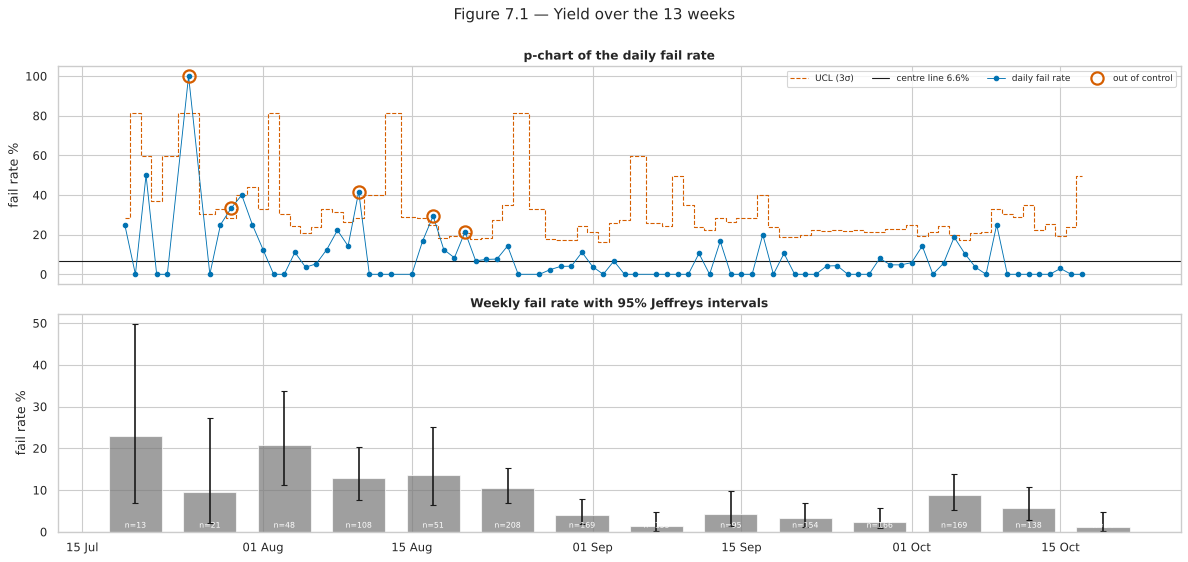

Days out of control: 5 of 86
Fail rate, first half of runs: 8.6%  vs  second half: 4.7%  (ratio 1.8x, Fisher p = 2.3e-03)
Spearman correlation of failure with run order: rho = -0.117, p = 3.1e-06


In [13]:
day = lab.set_index('timestamp').resample('D')['fail'].agg(['sum', 'count'])
day = day[day['count'] > 0].copy()
pbar = y.mean()
day['p'] = day['sum'] / day['count']
day['ucl'] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / day['count'])
day['lcl'] = (pbar - 3 * np.sqrt(pbar * (1 - pbar) / day['count'])).clip(lower=0)
day['out'] = (day['p'] > day['ucl']) | (day['p'] < day['lcl'])
week = lab.set_index('timestamp').resample('W')['fail'].agg(['sum', 'count'])
week['p'] = week['sum'] / week['count']
ci = np.array([stats.beta.ppf([0.025, 0.975], k + 0.5, n - k + 0.5) for k, n in zip(week['sum'], week['count'])])

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
ax = axes[0]
ax.step(day.index, day['ucl'] * 100, where='mid', color=C_FAIL, lw=1, ls='--', label='UCL (3σ)')
ax.axhline(pbar * 100, color='k', lw=1, label=f'centre line {pbar * 100:.1f}%')
ax.plot(day.index, day['p'] * 100, 'o-', color=C_PASS, ms=4, lw=0.8, label='daily fail rate')
ax.plot(day.index[day.out], day['p'][day.out] * 100, 'o', mfc='none', mec=C_FAIL, ms=11, mew=2, label='out of control')
ax.set(ylabel='fail rate %', title='p-chart of the daily fail rate'); ax.legend(ncol=4, fontsize=8)
ax = axes[1]
ax.bar(week.index, week['p'] * 100, width=5, color=C_GREY, alpha=0.7)
ax.errorbar(week.index, week['p'] * 100, yerr=[week['p'] * 100 - ci[:, 0] * 100, ci[:, 1] * 100 - week['p'] * 100], fmt='none', ecolor='k', capsize=3)
for t, n in zip(week.index, week['count']): ax.text(t, 1, f'n={n}', ha='center', fontsize=7, color='w')
ax.set(ylabel='fail rate %', title='Weekly fail rate with 95% Jeffreys intervals')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle('Figure 7.1 — Yield over the 13 weeks', y=1.0); fig.tight_layout(); savefig(fig, '07_01_p_chart')

half = len(lab) // 2
f1, f2 = y[:half].mean(), y[half:].mean()
tab = [[y[:half].sum(), half - y[:half].sum()], [y[half:].sum(), len(y) - half - y[half:].sum()]]
p_half = stats.fisher_exact(tab)[1]
rho_t, p_t = stats.spearmanr(lab['run'], y)
print(f'Days out of control: {int(day.out.sum())} of {len(day)}')
print(f'Fail rate, first half of runs: {100 * f1:.1f}%  vs  second half: {100 * f2:.1f}%  (ratio {f1 / f2:.1f}x, Fisher p = {p_half:.1e})')
print(f'Spearman correlation of failure with run order: rho = {rho_t:.3f}, p = {p_t:.1e}')

**Reading Figure 7.1.** The fail rate is not stable. Most of the early weeks run at 10–23% failures, far above the 6.6% centre line, and the out-of-control days on the p-chart are all in that early stretch; from September the rate settles at 1–6%. Over the whole period the fail rate in the first half of the runs is about twice the second half (8.6% vs 4.7%).

**Why this matters for everything that follows.** The sensors were also changing over those weeks (process tuning, consumables, recipe changes). A sensor whose level simply drifted downward while yield improved will look like a "failure predictor" in a naive comparison. §9 tests for exactly this. It also means a model trained on the early weeks will be calibrated to a fail rate that no longer exists in the later weeks (§11).

## 8. Q2 — Which sensors separate failing from passing runs?

**Method.** For each of the cleaned sensors, compare its values on failing vs passing runs with the **Mann-Whitney U test**. It compares ranks, so it does not assume normality and a few extreme values cannot drive it. Testing hundreds of sensors at once guarantees false positives at p < 0.05 (about 5% of them by chance alone), so p-values are corrected with **Benjamini-Hochberg** to control the false discovery rate at 5%.

**Effect size.** A small p-value is not a large effect. Each test also gives the **AUC**: the probability that a randomly chosen failing run has a higher value than a randomly chosen passing run. AUC = 0.5 means no separation; 0.6 or 0.4 is a modest effect. A sensor must pass both bars, q < 0.05 **and** |AUC − 0.5| ≥ 0.10, to count as a finding.

In [14]:
def screen(Xf, yf):
    rows = []
    for c in Xf.columns:
        v = Xf[c].to_numpy(); ok = ~np.isnan(v)
        a, b = v[ok & (yf == 1)], v[ok & (yf == 0)]
        if len(a) < 10 or len(b) < 10 or np.nanstd(v) == 0:
            continue
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        rows.append({'sensor': c, 'n_fail': len(a), 'n_pass': len(b), 'auc': u / (len(a) * len(b)), 'p': p,
                     'median_fail': np.median(a), 'median_pass': np.median(b)})
    r = pd.DataFrame(rows); r['q'] = bh(r['p']); r['effect'] = (r['auc'] - 0.5).abs()
    return r.sort_values('p').reset_index(drop=True)

scr = screen(X, y)
sig = scr[(scr.q < CONFIG['fdr_alpha']) & (scr.effect >= CONFIG['min_auc_effect'])].copy()
print(f'Sensors tested: {len(scr)}')
print(f'Raw p < 0.05: {(scr.p < 0.05).sum()}  (expected by chance alone: {0.05 * len(scr):.0f})')
print(f'BH q < 0.05: {(scr.q < 0.05).sum()};  of these with |AUC - 0.5| >= {CONFIG["min_auc_effect"]}: {len(sig)}')
print(f'Largest effect: {scr.loc[scr.effect.idxmax(), "sensor"]} with AUC {scr.auc[scr.effect.idxmax()]:.3f}')
display(sig.head(15)[['sensor', 'n_fail', 'n_pass', 'median_fail', 'median_pass', 'auc', 'p', 'q']].round(4))
scr.to_csv(OUT / 'sensor_screening.csv', index=False)

Sensors tested: 343
Raw p < 0.05: 68  (expected by chance alone: 17)
BH q < 0.05: 18;  of these with |AUC - 0.5| >= 0.1: 13
Largest effect: s059 with AUC 0.692


,sensor,n_fail,n_pass,median_fail,median_pass,auc,p,q
0,s059,104,1456,5.522,0.7223,0.692,0,0
1,s103,104,1461,-0.0082,-0.0102,0.6682,0,0
2,s247,71,781,0.0421,0.0262,0.6747,0,0.0001
3,s510,104,1461,58.23,46.38,0.636,0,0.0003
4,s205,104,1457,9.16,7.66,0.6193,0,0.0028
5,s129,104,1454,0,-0.1419,0.619,0,0.0028
6,s028,103,1462,68.16,69.24,0.3829,0.0001,0.0034
7,s033,104,1462,8.894,8.766,0.6106,0.0002,0.006
8,s341,104,1457,2.721,2.36,0.6095,0.0002,0.006
9,s316,104,1462,5.531,5.862,0.3907,0.0002,0.006


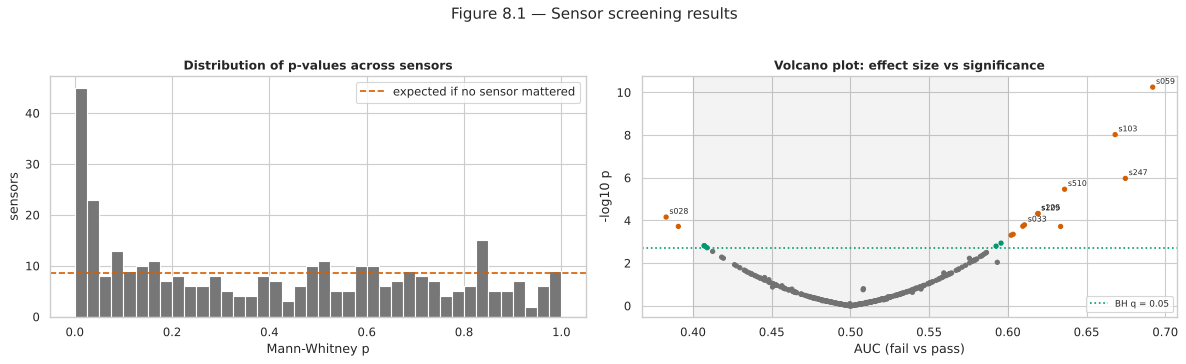

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]
ax.hist(scr.p, bins=40, color=C_GREY, edgecolor='w')
ax.axhline(len(scr) / 40, color=C_FAIL, ls='--', label='expected if no sensor mattered')
ax.set(title='Distribution of p-values across sensors', xlabel='Mann-Whitney p', ylabel='sensors'); ax.legend()
ax = axes[1]
col = np.where((scr.q < 0.05) & (scr.effect >= CONFIG['min_auc_effect']), C_FAIL, np.where(scr.q < 0.05, C_ACC, C_GREY))
ax.scatter(scr.auc, -np.log10(scr.p), c=col, s=14)
ax.axvspan(0.5 - CONFIG['min_auc_effect'], 0.5 + CONFIG['min_auc_effect'], color='k', alpha=0.05)
qline = scr.loc[scr.q < 0.05, 'p'].max() if (scr.q < 0.05).any() else np.nan
if np.isfinite(qline): ax.axhline(-np.log10(qline), color=C_ACC, ls=':', label='BH q = 0.05')
for _, r in sig.head(8).iterrows(): ax.annotate(r.sensor, (r.auc, -np.log10(r.p)), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set(title='Volcano plot: effect size vs significance', xlabel='AUC (fail vs pass)', ylabel='-log10 p'); ax.legend(fontsize=8)
fig.suptitle('Figure 8.1 — Sensor screening results', y=1.03); fig.tight_layout(); savefig(fig, '08_01_screening')

**Reading Figure 8.1.** The p-value histogram has a clear spike near zero above the flat line expected if no sensor mattered, so there is real signal: 68 sensors reach raw p < 0.05 where 17 would be expected by chance. After the false-discovery correction 18 remain, and 13 also pass the effect-size bar. The effects are modest, the largest AUC being 0.69 (s059). No single sensor comes close to separating fails from passes on its own, which is typical: yield loss in a fab usually has many small contributors rather than one smoking gun.

**Redundancy.** Several significant sensors may measure the same underlying process variable. Grouping them by correlation (|Spearman ρ| ≥ 0.90, hierarchical clustering) shows how many *independent* signals there really are.

In [16]:
S = sig['sensor'].tolist()
if len(S) >= 2:
    rho_s = X[S].rank().corr(min_periods=200).abs().fillna(0).to_numpy(copy=True)
    np.fill_diagonal(rho_s, 1)
    Z = hierarchy.linkage(squareform(1 - rho_s, checks=False), 'average')
    fam = hierarchy.fcluster(Z, 1 - CONFIG['redundancy_rho'], 'distance')
else:
    fam = np.ones(len(S), int)
sig['family'] = fam
fam_tab = (sig.sort_values('p').groupby('family')
              .agg(lead_sensor=('sensor', 'first'), members=('sensor', lambda s: ', '.join(s)), size=('sensor', 'size'),
                   best_auc=('auc', lambda a: a.iloc[np.argmax(np.abs(a - 0.5))]), best_p=('p', 'min'))
              .sort_values('best_p').reset_index(drop=True))
print(f'{len(S)} significant sensors collapse into {len(fam_tab)} independent signal families')
display(fam_tab.head(12))

13 significant sensors collapse into 11 independent signal families


,lead_sensor,members,size,best_auc,best_p
0,s059,s059,1,0.692,5.679e-11
1,s103,s103,1,0.6682,9.55e-09
2,s247,"s247, s385",2,0.6747,1.072e-06
3,s510,s510,1,0.636,3.453e-06
4,s205,"s205, s341",2,0.6193,4.717e-05
5,s129,s129,1,0.619,4.832e-05
6,s028,s028,1,0.3829,6.956e-05
7,s033,s033,1,0.6106,0.0001614
8,s316,s316,1,0.3907,0.0001907
9,s021,s021,1,0.6034,0.0004461


## 9. Q3 — Do those differences survive once the time trend is removed?

§7 showed the fail rate is much higher early in the period. Any sensor that also drifted over those weeks will *look* associated with failure even if it has nothing to do with it: both simply changed over time. This is the most common trap in fab data analysis.

**Two checks for each significant sensor:**
1. **Time association**: Spearman ρ between the sensor and run order.
2. **Detrended test**: subtract a centred rolling median over the neighbouring 101 runs (about two days of production) from the sensor, and from failure use the same idea by comparing each run only with its time neighbours. A sensor that still separates fails from passes *relative to runs made at the same time* carries information beyond the trend.
3. **Consistency over time**: the AUC computed separately in the first and second half of the period. A real signal should point the same way in both.

In [17]:
def detrend(s, w=CONFIG['detrend_window']):
    return s - s.rolling(w, center=True, min_periods=w // 4).median()

rows = []
for c in sig['sensor']:
    v = X[c]
    rt, pt = stats.spearmanr(lab['run'], v, nan_policy='omit')
    d = detrend(v).to_numpy(); ok = ~np.isnan(d)
    a, b = d[ok & (y == 1)], d[ok & (y == 0)]
    u, p_d = stats.mannwhitneyu(a, b)
    auc_h = []
    for part in (slice(0, half), slice(half, None)):
        vv, yy = v.to_numpy()[part], y[part]; o = ~np.isnan(vv)
        auc_h.append(roc_auc_score(yy[o], vv[o]) if yy[o].sum() >= 5 else np.nan)
    rows.append({'sensor': c, 'auc': sig.set_index('sensor').auc[c], 'rho_time': rt,
                 'auc_detrended': u / (len(a) * len(b)), 'p_detrended': p_d, 'auc_1st_half': auc_h[0], 'auc_2nd_half': auc_h[1]})
dtr = pd.DataFrame(rows); dtr['q_detrended'] = bh(dtr['p_detrended'])
dtr['same_direction'] = np.sign(dtr.auc_1st_half - 0.5) == np.sign(dtr.auc_2nd_half - 0.5)
dtr['survives'] = (dtr.q_detrended < CONFIG['fdr_alpha']) & ((dtr.auc_detrended - 0.5).abs() >= 0.05) & dtr.same_direction
dtr = dtr.merge(sig[['sensor', 'family']], on='sensor')
print(f'Significant sensors strongly tied to time (|rho_time| >= 0.3): {(dtr.rho_time.abs() >= 0.3).sum()} of {len(dtr)}')
print(f'Survive detrending (q < 0.05, |AUC_detrended - 0.5| >= 0.05, same direction in both halves): '
      f'{int(dtr.survives.sum())} sensors in {dtr.loc[dtr.survives, "family"].nunique()} families')
display(dtr.sort_values('p_detrended').round(3).head(15))
dtr.to_csv(OUT / 'sensor_detrended.csv', index=False)

Significant sensors strongly tied to time (|rho_time| >= 0.3): 9 of 13
Survive detrending (q < 0.05, |AUC_detrended - 0.5| >= 0.05, same direction in both halves): 6 sensors in 5 families


,sensor,auc,rho_time,auc_detrended,p_detrended,auc_1st_half,auc_2nd_half,q_detrended,same_direction,survives,family
0,s059,0.692,-0.442,0.613,0,0.723,0.572,0.001,True,True,5
4,s205,0.619,-0.211,0.609,0,0.628,0.557,0.001,True,True,1
8,s341,0.61,-0.201,0.605,0,0.625,0.536,0.001,True,True,1
11,s021,0.603,0.201,0.598,0.001,0.642,0.582,0.003,True,True,11
7,s033,0.611,-0.148,0.586,0.003,0.607,0.583,0.009,True,True,9
9,s316,0.391,0.353,0.428,0.014,0.418,0.391,0.03,True,True,7
3,s510,0.636,-0.415,0.556,0.055,0.599,0.63,0.103,True,False,4
1,s103,0.668,-0.524,0.551,0.079,0.622,0.645,0.12,True,False,3
5,s129,0.619,-0.31,0.551,0.083,0.528,0.675,0.12,True,False,6
12,s124,0.602,-0.326,0.548,0.104,0.493,0.646,0.136,False,False,10


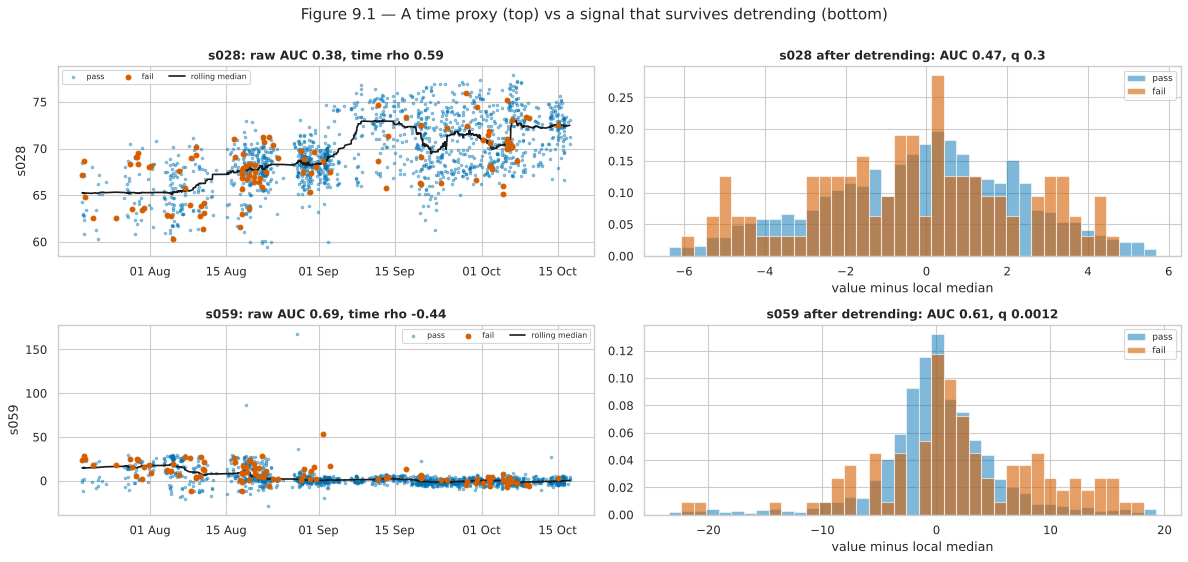

In [18]:
show = dtr.sort_values('p_detrended')
pick_real = show[show.survives].sensor.iloc[0] if show.survives.any() else show.sensor.iloc[0]
pick_time = dtr.loc[dtr.rho_time.abs().idxmax(), 'sensor']
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for row, c in enumerate([pick_time, pick_real]):
    v = X[c]; ax = axes[row, 0]
    ax.scatter(lab.timestamp[y == 0], v[y == 0], s=5, color=C_PASS, alpha=0.4, label='pass')
    ax.scatter(lab.timestamp[y == 1], v[y == 1], s=18, color=C_FAIL, label='fail', zorder=3)
    ax.plot(lab.timestamp, v.rolling(CONFIG['detrend_window'], center=True, min_periods=25).median(), color='k', lw=1.5, label='rolling median')
    r_ = dtr.set_index('sensor').loc[c]
    ax.set(title=f'{c}: raw AUC {r_.auc:.2f}, time rho {r_.rho_time:.2f}', ylabel=c); ax.legend(fontsize=7, ncol=3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax = axes[row, 1]; d = detrend(v)
    lo, hi = np.nanpercentile(d, [1, 99]); bins = np.linspace(lo, hi, 40)
    ax.hist(d[y == 0].dropna(), bins=bins, density=True, alpha=0.5, color=C_PASS, label='pass')
    ax.hist(d[y == 1].dropna(), bins=bins, density=True, alpha=0.6, color=C_FAIL, label='fail')
    ax.set(title=f'{c} after detrending: AUC {r_.auc_detrended:.2f}, q {r_.q_detrended:.2g}', xlabel='value minus local median'); ax.legend(fontsize=8)
fig.suptitle('Figure 9.1 — A time proxy (top) vs a signal that survives detrending (bottom)', y=1.0); fig.tight_layout(); savefig(fig, '09_01_detrend')

**Reading Figure 9.1 and the table.** Nine of the 13 significant sensors are strongly correlated with time (|ρ| ≥ 0.3). The top panel is a typical time proxy: its level moves steadily over the weeks, failures are concentrated in the early period, and once each run is compared with its neighbours the separation disappears. Several of the strongest raw findings fall into this group: s103 (raw AUC 0.67, time ρ = −0.52), s247 (0.67, ρ = −0.49) and s510 (0.64, ρ = −0.42) all lose significance after detrending.

**Six sensors survive**, in five independent families: s059, s205/s341 (one family), s021, s033 and s316. They still separate fails from passes relative to runs made at the same time, and point the same way in both halves of the period. Their detrended effects are modest (AUC 0.57–0.61, or 0.43 for s316, where *lower* values go with failure), so they are leads for engineering investigation, not pass/fail gates. s059 is worth noting: it is the strongest sensor raw and still among the strongest after detrending, but its effect is much weaker in the second half (AUC 0.72 → 0.57).

## 10. Q4 — Can classic SPC charts on these sensors be trusted?

**Setup.** A Shewhart individuals chart (I-chart) sets limits at the centre ± 3σ, where σ is estimated from the average moving range of a **phase I** reference period (here the first 500 runs, about the first five weeks). **Phase II** runs are then judged against those fixed limits. For an in-control, normally distributed, *independent* process, only about 0.27% of points should fall outside ±3σ.

**The catch: independence.** Fab sensors are often autocorrelated: consecutive runs share a chamber condition, a consumable or a recipe. Then the moving range underestimates the true spread, limits are too tight, and the chart floods operators with false alarms. Lag-1 autocorrelation is the quick test.

Sensors with lag-1 autocorrelation > 0.3 in phase I: 29 of 342 (8%)
Median share of phase II points beyond 3σ: 1.4% (theory for an independent, in-control process: 0.27%)
Autocorrelation vs false-alarm rate across sensors: Spearman rho = 0.17, p = 1.3e-03


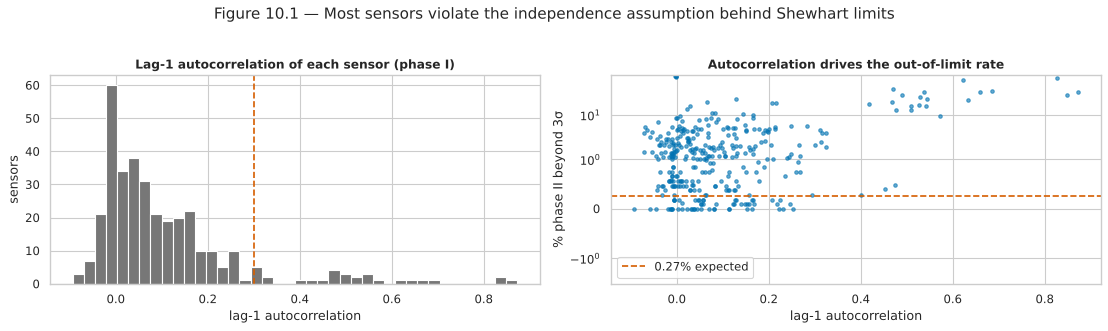

In [19]:
P1 = CONFIG['phase1_runs']
def lag1(v):
    v = pd.Series(v).dropna(); return v.autocorr(1) if len(v) > 50 else np.nan

def imr_limits(v):
    v = pd.Series(v).dropna(); mr = v.diff().abs().mean()
    sigma = mr / 1.128; c = v.mean()
    return c, sigma, v.std()

ac = pd.DataFrame({'sensor': SENSORS, 'lag1': [lag1(X[c].iloc[:P1]) for c in SENSORS]})
lims = [imr_limits(X[c].iloc[:P1]) for c in SENSORS]
ac['sd_over_mr_sigma'] = [s / sg if sg > 0 else np.nan for _, sg, s in lims]
viol = []
for c, (cen, sg, _) in zip(SENSORS, lims):
    v2 = X[c].iloc[P1:].dropna()
    viol.append(((v2 - cen).abs() > 3 * sg).mean() if sg > 0 and len(v2) else np.nan)
ac['phase2_beyond_3sigma'] = viol
ac = ac.dropna()
print(f'Sensors with lag-1 autocorrelation > 0.3 in phase I: {(ac.lag1 > 0.3).sum()} of {len(ac)} '
      f'({100 * (ac.lag1 > 0.3).mean():.0f}%)')
print(f'Median share of phase II points beyond 3σ: {100 * ac.phase2_beyond_3sigma.median():.1f}% (theory for an independent, '
      f'in-control process: 0.27%)')
rho_ac = stats.spearmanr(ac.lag1, ac.phase2_beyond_3sigma)
print(f'Autocorrelation vs false-alarm rate across sensors: Spearman rho = {rho_ac[0]:.2f}, p = {rho_ac[1]:.1e}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(ac.lag1, bins=40, color=C_GREY); axes[0].axvline(0.3, color=C_FAIL, ls='--')
axes[0].set(title='Lag-1 autocorrelation of each sensor (phase I)', xlabel='lag-1 autocorrelation', ylabel='sensors')
axes[1].scatter(ac.lag1, 100 * ac.phase2_beyond_3sigma, s=10, color=C_PASS, alpha=0.6)
axes[1].axhline(0.27, color=C_FAIL, ls='--', label='0.27% expected'); axes[1].set_yscale('symlog', linthresh=1)
axes[1].set(title='Autocorrelation drives the out-of-limit rate', xlabel='lag-1 autocorrelation', ylabel='% phase II beyond 3σ'); axes[1].legend()
fig.suptitle('Figure 10.1 — Most sensors violate the independence assumption behind Shewhart limits', y=1.03); fig.tight_layout(); savefig(fig, '10_01_autocorr')

**Individuals and EWMA charts for two contrasting sensors.** The Western Electric rules are checked on the I-chart: (1) one point beyond 3σ, (2) two of three beyond 2σ on the same side, (3) four of five beyond 1σ on the same side, (4) eight in a row on one side of the centre. The **EWMA** chart (λ = 0.2) averages recent points, so it detects small sustained shifts that a Shewhart chart misses.

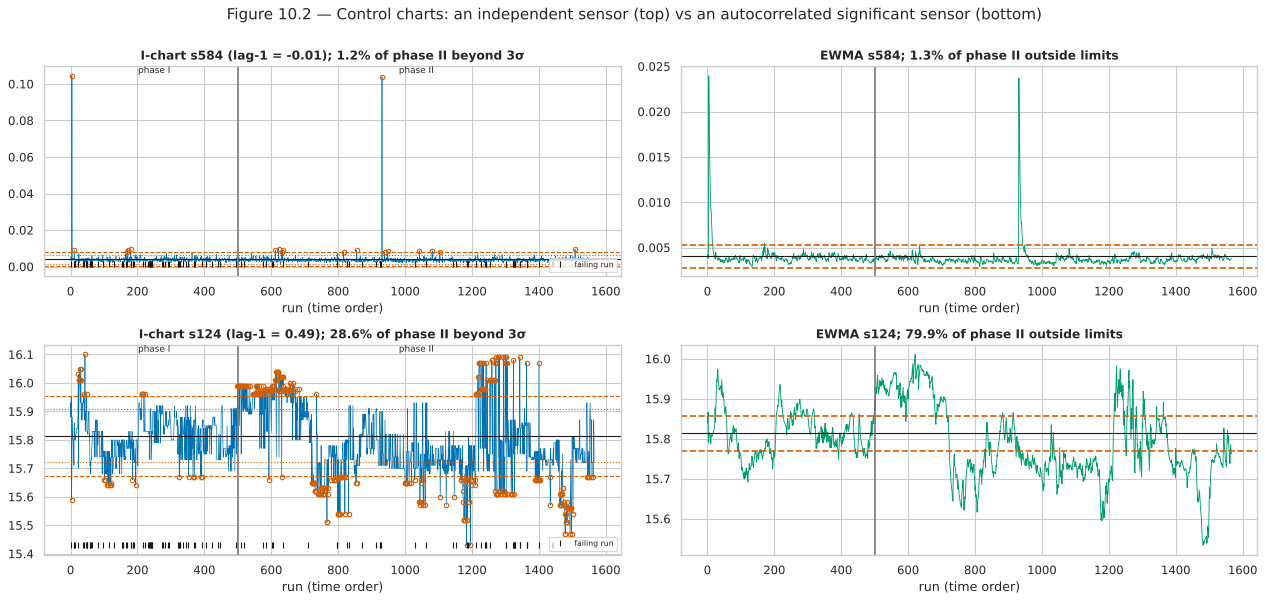

,sensor,lag1,sd / MR-sigma,R1 %,R2 %,R3 %,R4 %,EWMA out %
0,s584,-0.01,3.53,1.22,0,0.19,10.87,1.31
1,s124,0.49,1.67,28.58,52.11,62.7,47.42,79.94


In [20]:
def we_rules(z):
    z = pd.Series(z); flags = pd.DataFrame(index=z.index)
    flags['R1'] = z.abs() > 3
    for side in (1, -1):
        flags[f'R2{side}'] = ((side * z > 2).rolling(3).sum() >= 2)
        flags[f'R3{side}'] = ((side * z > 1).rolling(5).sum() >= 4)
        flags[f'R4{side}'] = ((side * z > 0).rolling(8).sum() == 8)
    out = pd.DataFrame({'R1': flags.R1, 'R2': flags['R21'] | flags['R2-1'], 'R3': flags['R31'] | flags['R3-1'], 'R4': flags['R41'] | flags['R4-1']})
    return out

def ewma(v, lam, cen):
    out = np.empty(len(v)); prev = cen
    for i, x in enumerate(v): prev = lam * x + (1 - lam) * prev; out[i] = prev
    return out

ac_i = ac.set_index('sensor')
spc_bad = ac_i.loc[[s for s in ac_i.index if s in set(sig.sensor)] or list(ac_i.index)].lag1.idxmax()
spc_good = ac_i[(ac_i.lag1.abs() < 0.1)].phase2_beyond_3sigma.sort_values().index[len(ac_i[(ac_i.lag1.abs() < 0.1)]) // 2]
spc_rows = []
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
for row, c in enumerate([spc_good, spc_bad]):
    v = X[c].ffill().bfill().to_numpy()
    cen, sg, sd = imr_limits(X[c].iloc[:P1])
    z = (v - cen) / sg
    rules = we_rules(z); r2 = rules.iloc[P1:]
    ax = axes[row, 0]
    ax.plot(lab.run, v, lw=0.6, color=C_PASS)
    for k, ls in [(3, '--'), (2, ':')]:
        ax.axhline(cen + k * sg, color=C_FAIL, ls=ls, lw=1); ax.axhline(cen - k * sg, color=C_FAIL, ls=ls, lw=1)
    ax.axhline(cen, color='k', lw=1); ax.axvline(P1, color=C_GREY, lw=1.5)
    o = np.where(rules.R1)[0]; ax.plot(o, v[o], 'o', mfc='none', mec=C_FAIL, ms=4)
    fy = np.where(y == 1)[0]; ax.plot(fy, np.full(len(fy), np.nanmin(v)), '|', color='k', ms=6, label='failing run')
    ax.text(P1 / 2, ax.get_ylim()[1], 'phase I', ha='center', va='top', fontsize=8); ax.text(P1 + (len(v) - P1) / 2, ax.get_ylim()[1], 'phase II', ha='center', va='top', fontsize=8)
    ax.set(title=f'I-chart {c} (lag-1 = {ac_i.lag1[c]:.2f}); {100 * r2.R1.mean():.1f}% of phase II beyond 3σ', xlabel='run (time order)')
    ax.legend(fontsize=7, loc='lower right')
    lam, L = CONFIG['ewma_lambda'], CONFIG['ewma_L']
    e = ewma(v, lam, cen); h = L * sg * np.sqrt(lam / (2 - lam))
    ax = axes[row, 1]
    ax.plot(lab.run, e, lw=0.8, color=C_ACC); ax.axhline(cen + h, color=C_FAIL, ls='--'); ax.axhline(cen - h, color=C_FAIL, ls='--')
    ax.axhline(cen, color='k', lw=1); ax.axvline(P1, color=C_GREY, lw=1.5)
    ew_out = (np.abs(e[P1:] - cen) > h).mean()
    ax.set(title=f'EWMA {c}; {100 * ew_out:.1f}% of phase II outside limits', xlabel='run (time order)')
    spc_rows.append({'sensor': c, 'lag1': ac_i.lag1[c], 'sd / MR-sigma': sd / sg, **{f'{k} %': 100 * r2[k].mean() for k in rules.columns},
                     'EWMA out %': 100 * ew_out})
fig.suptitle('Figure 10.2 — Control charts: an independent sensor (top) vs an autocorrelated significant sensor (bottom)', y=1.0)
fig.tight_layout(); savefig(fig, '10_02_charts')
display(pd.DataFrame(spc_rows).round(2))

**A fix for autocorrelated sensors: chart the residuals.** Fit a simple AR(1) model on phase I, x_t = c + φ·x_(t−1) + e_t, and chart the one-step-ahead residuals e_t instead of the raw values. The residuals are close to independent, so standard limits regain their meaning, and a residual outside the limits means "this run is surprising given the previous run".

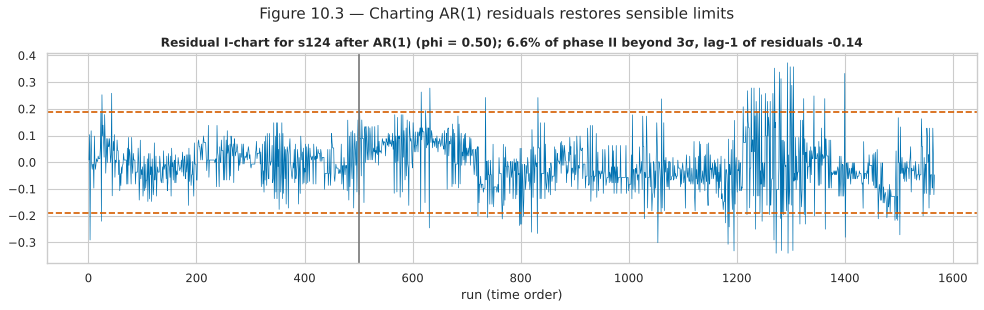

In [21]:
def ar1_resid(v, n1):
    v = pd.Series(v).ffill().bfill().to_numpy()
    xp, xc = v[:n1 - 1], v[1:n1]
    phi, c0 = np.polyfit(xp, xc, 1)
    res = v[1:] - (c0 + phi * v[:-1])
    return np.r_[np.nan, res], phi

res, phi = ar1_resid(X[spc_bad], P1)
cen_r, sg_r, _ = imr_limits(res[1:P1])
out_r = (np.abs(res[P1:] - cen_r) > 3 * sg_r).mean()
fig, ax = plt.subplots(figsize=(15, 3.4))
ax.plot(lab.run, res, lw=0.6, color=C_PASS); ax.axhline(cen_r + 3 * sg_r, color=C_FAIL, ls='--'); ax.axhline(cen_r - 3 * sg_r, color=C_FAIL, ls='--')
ax.axvline(P1, color=C_GREY, lw=1.5)
ax.set(title=f'Residual I-chart for {spc_bad} after AR(1) (phi = {phi:.2f}); {100 * out_r:.1f}% of phase II beyond 3σ, lag-1 of residuals {lag1(res[1:P1]):.2f}',
       xlabel='run (time order)')
fig.suptitle('Figure 10.3 — Charting AR(1) residuals restores sensible limits', y=1.05); savefig(fig, '10_03_residual_chart')

**Reading §10.** Autocorrelation is common rather than rare: 8% of sensors have lag-1 autocorrelation above 0.3, and across all sensors the median phase II out-of-limit rate (1.4%) is five times the theoretical 0.27%, with the most autocorrelated sensors the worst (Figure 10.1). The two charts in Figure 10.2 show the consequence. The nearly independent sensor s584 behaves close to theory on the 3σ rule (1.2% beyond 3σ), although its long runs on one side of the centre line (rule 4) show the level is not perfectly stable. The autocorrelated sensor s124 is unusable as charted: 29% of phase II runs breach 3σ and its EWMA chart is out of limits most of the time. Its sample standard deviation is 1.7× the moving-range sigma, so the limits are far too tight.

Charting the AR(1) residuals of s124 (Figure 10.3) removes the run-to-run correlation (residual lag-1 ≈ −0.14) and cuts the out-of-limit rate to about 7%. That is a large improvement but still far from 0.27%, which says the sensor's *level* shifts between phase I and phase II as well. In practice that means phase I limits must be re-baselined after known process changes, or a level-shift chart (EWMA/CUSUM on the residuals) used.

**Practical rule for the line:** check lag-1 autocorrelation before setting Shewhart limits on any sensor; for autocorrelated sensors, chart model residuals or use limits based on the overall standard deviation, otherwise operators learn to ignore the alarms.

## 11. Q5 — Can a model flag failing runs before final test?

### 11.1 Evaluation protocol

A fab would deploy such a model on **future** runs, so the honest test is a **time-ordered split**: models are developed on the first 70% of runs and evaluated once on the last 30%, which no step below has touched. A random split would let the model learn "what week it is" (§7, §9) and report optimistic accuracy. Both are reported so the difference is visible.

| Choice | Setting | Reason |
|---|---|---|
| Primary metric | **PR-AUC** (average precision) | With 6.6% fails, ROC-AUC looks good even for weak models; PR-AUC focuses on the fail class |
| Baseline | No-skill PR-AUC = fail rate of the test block | Anything near it is chance |
| Operating point | Flag the riskiest 10% of runs; report recall and precision | What an engineer would actually act on |
| Uncertainty | 2,000 bootstrap resamples of the test block | Only about 20 test fails: intervals will be wide |
| Chance check | Refit on training data with shuffled labels (200 times for logistic regression, 50 for gradient boosting) | Does the real model beat models that learned nothing? |
| Pre-processing | Median imputation + missing-value indicators + scaling, **fitted inside each training fold** | No information leaks from evaluation data |

In [22]:
n_test = int(round(CONFIG['test_share'] * len(lab)))
tr, te = np.arange(len(lab) - n_test), np.arange(len(lab) - n_test, len(lab))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y[tr], y[te]
split_tab = pd.DataFrame({'block': ['development (train)', 'sealed test'], 'runs': [len(tr), len(te)], 'fails': [ytr.sum(), yte.sum()],
                          'fail rate %': [100 * ytr.mean(), 100 * yte.mean()],
                          'from': [lab.timestamp.iloc[tr[0]], lab.timestamp.iloc[te[0]]], 'to': [lab.timestamp.iloc[tr[-1]], lab.timestamp.iloc[te[-1]]]})
display(split_tab)

def l1_logistic(C):
    """L1-penalised logistic regression; scikit-learn 1.8 replaced penalty='l1' with l1_ratio=1, so pick the right spelling."""
    major, minor = (int(x) for x in sklearn.__version__.split('.')[:2])
    kw = {'l1_ratio': 1.0} if (major, minor) >= (1, 8) else {'penalty': 'l1'}
    return LogisticRegression(C=C, solver='liblinear', class_weight='balanced', max_iter=2000, **kw)

MODELS = {
    'No skill (prior)': DummyClassifier(strategy='prior'),
    'L1 logistic regression': make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), l1_logistic(C=0.05)),
    'Gradient boosting': make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                       HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1, max_iter=100, l2_regularization=1.0,
                                                                      class_weight='balanced', random_state=CONFIG['seed'])),
}

def at_alarm(yt, s, rate=CONFIG['alarm_rate'], thr=None):
    thr = np.quantile(s, 1 - rate) if thr is None else thr
    flag = s >= thr
    return {'recall': flag[yt == 1].mean() if yt.sum() else np.nan, 'precision': yt[flag].mean() if flag.any() else np.nan,
            'alarms %': 100 * flag.mean(), 'fails caught': int(flag[yt == 1].sum())}

,block,runs,fails,fail rate %,from,to
0,development (train),1097,78,7.11,2008-07-19 11:55:00,2008-09-26 03:12:00
1,sealed test,470,26,5.532,2008-09-26 03:29:00,2008-10-17 06:07:00


### 11.2 Cross-validation inside the development block: random vs time-ordered folds

In [23]:
cv_rows, oof = [], {}
for name, m in MODELS.items():
    for cvname, cv in [('random 5-fold', StratifiedKFold(5, shuffle=True, random_state=CONFIG['seed'])), ('time-ordered 5-fold', TimeSeriesSplit(5))]:
        scores = []
        for a, b in cv.split(Xtr, ytr):
            if ytr[b].sum() == 0 or ytr[a].sum() == 0: continue
            mm = clone(m).fit(Xtr.iloc[a], ytr[a]); s = mm.predict_proba(Xtr.iloc[b])[:, 1]
            scores.append((average_precision_score(ytr[b], s), ytr[b].mean(), roc_auc_score(ytr[b], s)))
        sc = np.array(scores)
        cv_rows.append({'model': name, 'folds': cvname, 'PR-AUC mean': sc[:, 0].mean(), 'no-skill PR-AUC': sc[:, 1].mean(),
                        'lift over no-skill': sc[:, 0].mean() / sc[:, 1].mean(), 'ROC-AUC mean': sc[:, 2].mean(), 'n folds': len(sc)})
cv_tab = pd.DataFrame(cv_rows)
display(cv_tab.round(3))

,model,folds,PR-AUC mean,no-skill PR-AUC,lift over no-skill,ROC-AUC mean,n folds
0,No skill (prior),random 5-fold,0.071,0.071,1,0.5,5
1,No skill (prior),time-ordered 5-fold,0.056,0.056,1,0.5,5
2,L1 logistic regression,random 5-fold,0.176,0.071,2.48,0.725,5
3,L1 logistic regression,time-ordered 5-fold,0.148,0.056,2.643,0.577,5
4,Gradient boosting,random 5-fold,0.244,0.071,3.435,0.77,5
5,Gradient boosting,time-ordered 5-fold,0.189,0.056,3.372,0.585,5


In [24]:
ct = cv_tab.set_index(['model', 'folds'])
g_r, g_t = ct.loc[('Gradient boosting', 'random 5-fold')], ct.loc[('Gradient boosting', 'time-ordered 5-fold')]
l_r, l_t = ct.loc[('L1 logistic regression', 'random 5-fold')], ct.loc[('L1 logistic regression', 'time-ordered 5-fold')]
note(f'**Reading the cross-validation table.** With random folds, gradient boosting reaches PR-AUC {g_r["PR-AUC mean"]:.3f} '
     f'({g_r["lift over no-skill"]:.1f}× the no-skill level) and ROC-AUC {g_r["ROC-AUC mean"]:.2f}. With time-ordered folds, where every '
     f'fold is predicted only from earlier runs, ROC-AUC drops to {g_t["ROC-AUC mean"]:.2f} for gradient boosting and {l_t["ROC-AUC mean"]:.2f} '
     f'for logistic regression, close to the 0.5 of a coin toss. Random folds let the model learn which *period* a run belongs to, and '
     f'period predicts failure here (§7). Only the time-ordered numbers say anything about future production, and they are the ones the '
     f'sealed test below should be compared with.')

**Reading the cross-validation table.** With random folds, gradient boosting reaches PR-AUC 0.244 (3.4× the no-skill level) and ROC-AUC 0.77. With time-ordered folds, where every fold is predicted only from earlier runs, ROC-AUC drops to 0.59 for gradient boosting and 0.58 for logistic regression, close to the 0.5 of a coin toss. Random folds let the model learn which *period* a run belongs to, and period predicts failure here (§7). Only the time-ordered numbers say anything about future production, and they are the ones the sealed test below should be compared with.

### 11.3 One evaluation on the sealed test block

In [25]:
fitted, test_rows, test_scores = {}, [], {}
for name, m in MODELS.items():
    mm = clone(m).fit(Xtr, ytr); fitted[name] = mm
    s_tr = mm.predict_proba(Xtr)[:, 1]; s = mm.predict_proba(Xte)[:, 1]; test_scores[name] = s
    thr = np.quantile(s_tr, 1 - CONFIG['alarm_rate'])     # threshold fixed on training data, as it would be in deployment
    boot = []
    for _ in range(CONFIG['bootstrap_draws']):
        i = RNG.integers(0, len(yte), len(yte))
        if yte[i].sum() > 0: boot.append(average_precision_score(yte[i], s[i]))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    test_rows.append({'model': name, 'PR-AUC': average_precision_score(yte, s), 'PR-AUC 95% CI': f'{lo:.3f} – {hi:.3f}',
                      'ROC-AUC': roc_auc_score(yte, s), **{f'{k} @10% (train thr)': v for k, v in at_alarm(yte, s, thr=thr).items()}})
test_tab = pd.DataFrame(test_rows)
print(f'No-skill PR-AUC on the test block = {yte.mean():.3f} ({yte.sum()} fails in {len(yte)} runs)')
display(test_tab.round(3))

No-skill PR-AUC on the test block = 0.055 (26 fails in 470 runs)


,model,PR-AUC,PR-AUC 95% CI,ROC-AUC,recall @10% (train thr),precision @10% (train thr),alarms % @10% (train thr),fails caught @10% (train thr)
0,No skill (prior),0.055,0.036 – 0.077,0.5,1,0.055,100,26
1,L1 logistic regression,0.066,0.041 – 0.119,0.549,0,0,0.213,0
2,Gradient boosting,0.066,0.042 – 0.108,0.577,0,0,2.553,0


**Is that better than chance?** The training labels are shuffled (200 times for logistic regression, 50 for gradient boosting); each time the model is refitted and scored on the real test block. If the real model's PR-AUC sits inside this null distribution, it has not learned anything that transfers to future runs.

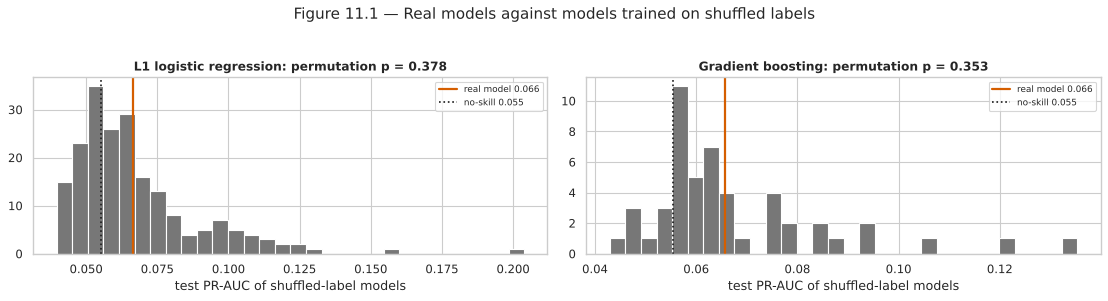

,model,real PR-AUC,null median,null 95th pct,permutation p
0,L1 logistic regression,0.066,0.062,0.111,0.378
1,Gradient boosting,0.066,0.062,0.101,0.353


(permutation tests took 644 s)


In [26]:
t0 = time.time(); perm = {}
for name in ['L1 logistic regression', 'Gradient boosting']:
    vals = []
    n_perm = CONFIG['n_permutations'] if name.startswith('L1') else CONFIG['n_permutations_gb']
    for k in range(n_perm):
        yp = RNG.permutation(ytr)
        vals.append(average_precision_score(yte, clone(MODELS[name]).fit(Xtr, yp).predict_proba(Xte)[:, 1]))
    perm[name] = np.array(vals)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
perm_rows = []
for ax, (name, vals) in zip(axes, perm.items()):
    real = test_tab.set_index('model').loc[name, 'PR-AUC']
    p_perm = (1 + (vals >= real).sum()) / (1 + len(vals))
    perm_rows.append({'model': name, 'real PR-AUC': real, 'null median': np.median(vals), 'null 95th pct': np.percentile(vals, 95), 'permutation p': p_perm})
    ax.hist(vals, bins=30, color=C_GREY); ax.axvline(real, color=C_FAIL, lw=2, label=f'real model {real:.3f}')
    ax.axvline(yte.mean(), color='k', ls=':', label=f'no-skill {yte.mean():.3f}')
    ax.set(title=f'{name}: permutation p = {p_perm:.3f}', xlabel='test PR-AUC of shuffled-label models'); ax.legend(fontsize=8)
fig.suptitle('Figure 11.1 — Real models against models trained on shuffled labels', y=1.04); fig.tight_layout(); savefig(fig, '11_01_permutation')
perm_tab = pd.DataFrame(perm_rows); display(perm_tab.round(3))
print(f'(permutation tests took {time.time() - t0:.0f} s)')

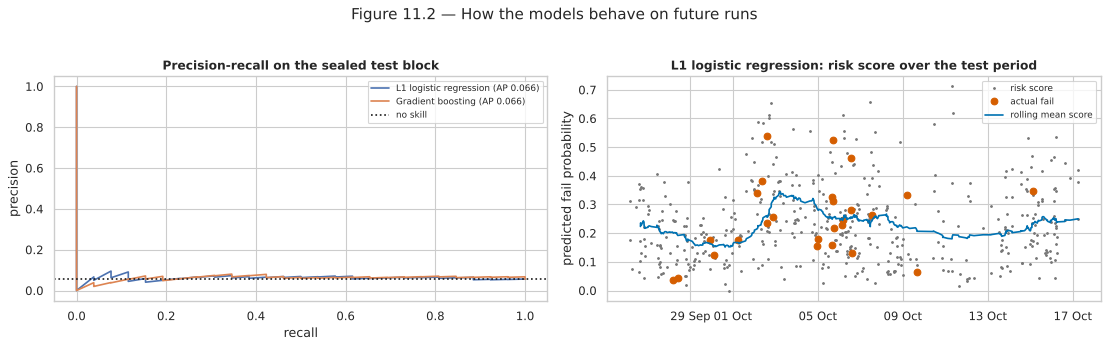

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for name, s in test_scores.items():
    if name.startswith('No'): continue
    p_, r_, _ = precision_recall_curve(yte, s)
    axes[0].plot(r_, p_, lw=1.5, label=f'{name} (AP {average_precision_score(yte, s):.3f})')
axes[0].axhline(yte.mean(), color='k', ls=':', label='no skill'); axes[0].set(title='Precision-recall on the sealed test block', xlabel='recall', ylabel='precision'); axes[0].legend(fontsize=8)
best = max(['L1 logistic regression', 'Gradient boosting'], key=lambda n: average_precision_score(yte, test_scores[n]))
s = test_scores[best]
roll = pd.Series(s).rolling(50, min_periods=10).mean()
axes[1].plot(lab.timestamp.iloc[te], s, '.', color=C_GREY, ms=3, label='risk score')
axes[1].plot(lab.timestamp.iloc[te][yte == 1], s[yte == 1], 'o', color=C_FAIL, ms=6, label='actual fail')
axes[1].plot(lab.timestamp.iloc[te], roll, color=C_PASS, lw=1.5, label='rolling mean score')
axes[1].set(title=f'{best}: risk score over the test period', ylabel='predicted fail probability'); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle('Figure 11.2 — How the models behave on future runs', y=1.03); fig.tight_layout(); savefig(fig, '11_02_pr_curves')

### 11.4 Which inputs does the model rely on?

Permutation importance on the test block: shuffle one sensor at a time and measure the drop in PR-AUC. Sensors whose shuffling costs nothing are not used in any way that generalises.

In [28]:
mm = fitted['Gradient boosting']
pi = permutation_importance(mm, Xte, yte, scoring='average_precision', n_repeats=10, random_state=CONFIG['seed'], n_jobs=1)
imp = pd.DataFrame({'sensor': SENSORS, 'importance': pi.importances_mean, 'sd': pi.importances_std}).sort_values('importance', ascending=False)
imp['in screening list'] = imp.sensor.isin(sig.sensor)
imp['survives detrending'] = imp.sensor.isin(dtr.loc[dtr.survives, 'sensor'])
display(imp.head(10).round(4))
lr = fitted['L1 logistic regression'][-1]
n_feat_in = fitted['L1 logistic regression'][:-1].transform(Xtr.iloc[:5]).shape[1]
print(f'L1 logistic regression keeps {int((lr.coef_ != 0).sum())} of {n_feat_in} inputs (sensors + missing indicators)')

,sensor,importance,sd,in screening list,survives detrending
90,s102,0.0043,0.0014,False,False
31,s033,0.0028,0.0017,True,True
112,s129,0.0026,0.0031,True,False
81,s091,0.0025,0.0011,False,False
19,s021,0.0023,0.0013,True,True
2,s002,0.0022,0.0006,False,False
100,s117,0.0021,0.0012,False,False
142,s163,0.0021,0.0011,False,False
173,s205,0.0018,0.0005,True,True
297,s488,0.0016,0.0019,False,False


L1 logistic regression keeps 109 of 575 inputs (sensors + missing indicators)


In [29]:
tt = test_tab.set_index('model'); pp = perm_tab.set_index('model')
best_m = tt.drop('No skill (prior)')['PR-AUC'].idxmax()
alarm_col = 'alarms % @10% (train thr)'
note(f'**Reading §11.3–11.4.** On the sealed test block (the last {len(te)} runs, {yte.sum()} failures) the best model, {best_m}, reaches '
     f'PR-AUC {tt.loc[best_m, "PR-AUC"]:.3f} against a no-skill level of {yte.mean():.3f}, with a 95% interval of {tt.loc[best_m, "PR-AUC 95% CI"]} '
     f'that includes the no-skill level. The permutation test settles it: models trained on shuffled labels score as well '
     f'(permutation p = {pp.loc["L1 logistic regression", "permutation p"]:.2f} for logistic regression, '
     f'{pp.loc["Gradient boosting", "permutation p"]:.2f} for gradient boosting). **Neither model has learned anything that transfers to future runs.**\n\n'
     f'The alarm threshold shows a second, practical failure. A threshold set on training data to flag 10% of runs flags only '
     f'{tt.loc["L1 logistic regression", alarm_col]:.1f}% (logistic) and {tt.loc["Gradient boosting", alarm_col]:.1f}% (boosting) of test runs, '
     f'catching {int(tt.loc[best_m, "fails caught @10% (train thr)"])} of {yte.sum()} failures: the score distribution itself drifted, so a deployed '
     f'model would quietly stop alarming. The permutation importances are tiny, and only a few of the top inputs are sensors that survived '
     f'detrending in §9.\n\n'
     f'**What this means.** This is a useful negative result, not a failed analysis. With about 100 failures, 343 sensors and a process that changes '
     f'week to week, the data cannot support a reliable pass/fail predictor. A fab would get more from monitoring the drift-robust sensors (§9) '
     f'and adding the missing context (tool, chamber, lot, recipe) than from a more complex model.')

**Reading §11.3–11.4.** On the sealed test block (the last 470 runs, 26 failures) the best model, L1 logistic regression, reaches PR-AUC 0.066 against a no-skill level of 0.055, with a 95% interval of 0.041 – 0.119 that includes the no-skill level. The permutation test settles it: models trained on shuffled labels score as well (permutation p = 0.38 for logistic regression, 0.35 for gradient boosting). **Neither model has learned anything that transfers to future runs.**

The alarm threshold shows a second, practical failure. A threshold set on training data to flag 10% of runs flags only 0.2% (logistic) and 2.6% (boosting) of test runs, catching 0 of 26 failures: the score distribution itself drifted, so a deployed model would quietly stop alarming. The permutation importances are tiny, and only a few of the top inputs are sensors that survived detrending in §9.

**What this means.** This is a useful negative result, not a failed analysis. With about 100 failures, 343 sensors and a process that changes week to week, the data cannot support a reliable pass/fail predictor. A fab would get more from monitoring the drift-robust sensors (§9) and adding the missing context (tool, chamber, lot, recipe) than from a more complex model.

## 12. Answers, recommendations and limitations

| Question | Answer | Evidence |
|---|---|---|
| Q1 Is yield stable? | **No.** The fail rate halves from the first to the second half of the period | §7: 8.6% vs 4.7%, Fisher p = 0.002; 5 out-of-control days on the p-chart |
| Q2 Which sensors separate fail from pass? | 13 sensors (11 families) after false-discovery correction and an effect-size bar; effects are modest | §8: max AUC 0.69; 68 raw hits vs 17 expected by chance |
| Q3 Do they survive removing the trend? | **6 sensors in 5 families do**; most of the strongest raw sensors are time proxies | §9: s059, s205/s341, s021, s033, s316 |
| Q4 Can Shewhart charts be trusted? | Not as textbook limits; autocorrelation and level shifts inflate false alarms | §10: median 1.4% beyond 3σ vs 0.27%; s124 29% → about 7% with AR(1) residuals |
| Q5 Can a model flag failures in advance? | **No better than chance on future runs** | §11: PR-AUC ≈ 0.07 vs 0.055; permutation p ≈ 0.35 |

**Recommendations to the fab**
1. **Put the 5 drift-robust signal families under monitoring** with EWMA or residual charts, and review them with the owners of the corresponding process steps. They are the best leads in this data.
2. **Check autocorrelation before setting control limits** on any sensor, and re-baseline phase I limits after known process changes. Otherwise alarms become noise and operators learn to ignore them.
3. **Track yield with a p-chart** and annotate process changes on it; the early-period excursion is the biggest effect in this dataset and its cause is not recorded here.
4. **Do not deploy a pass/fail model on these sensors yet.** Collect process context (tool, chamber, recipe, lot) and more failures first, then revisit with a time-ordered evaluation.

**Limitations**
* Sensors are anonymised: no finding can be tied to a physical step, and no specification limits are available, so process capability (Cpk) cannot be computed.
* Observational data: associations, not causes. Detrending removes the slow trend but not every possible confounder.
* Only 104 failures (26 in the test block), so all model metrics have wide intervals.
* The labels come from one quarter of 2008 on one line; results may not transfer to other products or tools.

## 13. Reproducibility record

The headline numbers below are recomputed from this run. If anything in the narrative disagrees with them, the numbers below are correct.

In [30]:
headline = {
    'runs': len(lab), 'fails': int(y.sum()), 'fail_rate_pct': round(100 * y.mean(), 2),
    'sensors_after_cleaning': len(SENSORS),
    'fail_rate_first_half_pct': round(100 * f1, 1), 'fail_rate_second_half_pct': round(100 * f2, 1),
    'p_chart_days_out_of_control': int(day.out.sum()),
    'sensors_q_lt_0.05': int((scr.q < 0.05).sum()), 'sensors_significant_and_large': len(sig), 'signal_families': len(fam_tab),
    'sensors_surviving_detrending': int(dtr.survives.sum()),
    'share_sensors_lag1_gt_0.3_pct': round(100 * (ac.lag1 > 0.3).mean(), 1),
    'median_phase2_beyond_3sigma_pct': round(100 * ac.phase2_beyond_3sigma.median(), 2),
    'test_no_skill_pr_auc': round(yte.mean(), 3),
    **{f'test_pr_auc_{k.split()[0].lower()}': round(v, 3) for k, v in test_tab.set_index('model')['PR-AUC'].items()},
    **{f'perm_p_{k.split()[0].lower()}': round(v, 3) for k, v in perm_tab.set_index('model')['permutation p'].items()},
    'data_sha256': {k: v[:16] for k, v in hashes.items()},
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__},
}
json.dump(headline, open(OUT / 'headline_numbers.json', 'w'), indent=1, default=str)
for k, v in headline.items(): print(f'{k:<36} {v}')

runs                                 1567
fails                                104
fail_rate_pct                        6.64
sensors_after_cleaning               343
fail_rate_first_half_pct             8.6
fail_rate_second_half_pct            4.7
p_chart_days_out_of_control          5
sensors_q_lt_0.05                    18
sensors_significant_and_large        13
signal_families                      11
sensors_surviving_detrending         6
share_sensors_lag1_gt_0.3_pct        8.5
median_phase2_beyond_3sigma_pct      1.41
test_no_skill_pr_auc                 0.055
test_pr_auc_no                       0.055
test_pr_auc_l1                       0.066
test_pr_auc_gradient                 0.066
perm_p_l1                            0.378
perm_p_gradient                      0.353
data_sha256                          {'secom.data': '20f0e7ee434f7dcb', 'secom_labels.data': '126884cf453705c9'}
versions                             {'python': '3.13.17', 'numpy': '2.5.3', 'pandas': '3.0.5', 'skl